# Churn télécom — Analyse et sélection des variables d’origine

L’objectif est de comparer un modèle utilisant les huit variables sources à un modèle utilisant seulement les variables retenues. **Aucune nouvelle feature prédictive n’est créée.**

- Partie 1 : fonctions communes de préparation, analyse, sélection et affichage.
- Partie 2 : analyses catégorielles et numériques, validation des retraits, puis bilan de test.

La version avec feature engineering est conservée dans `old/telco_churn_modeling_with_feature_engineering.ipynb`. Cette nouvelle version est écrite sans exécuter analyses, tests ou modèles.


## Partie 1.1 — Imports et configuration

Même cible à 30 jours et mêmes huit colonnes sources. Les données et résultats restent locaux.


In [32]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from catboost import CatBoostClassifier, EFstrType
from IPython.display import display
from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    precision_recall_curve,
)

# Ouvrir le notebook depuis la racine du projet ou depuis notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from settings import settings

SEED = 42
DATA_PATH = settings.DATA_PATH
MODEL_FEATURES = [
    "contract",
    "channel",
    "monthly_fee",
    "data_gb",
    "support_calls_3m",
    "late_payments",
    "nps",
    "last_invoice_amount",
]
CATEGORICAL_FEATURES = ["contract", "channel"]
NUMERIC_FEATURES = [
    "monthly_fee",
    "data_gb",
    "support_calls_3m",
    "late_payments",
    "nps",
    "last_invoice_amount",
]

LABEL_DELAY = pd.Timedelta(30, unit="D")
VALIDATION_MONTHS = ("2024-07", "2024-08", "2024-09")
TEST_MONTHS = ("2024-10", "2024-11")



## Partie 1.2 — Préparation et calendrier J+30

Les données sont nettoyées une fois. Train croissant et dernier mois mature réservé à l’early stopping. Chaque label utilisé doit satisfaire `snapshot_date + 30 jours <= scoring_date`. À la frontière J+30, on suppose le label chargé avant le fit.

| Mois prédit | Train | Early stopping | Rôle |
|---|---|---|---|
| Juillet | Janvier–mai | Juin | Validation |
| Août | Janvier–juin | Juillet | Validation |
| Septembre | Janvier–juillet | Août | Validation |
| Octobre | Janvier–août | Septembre | Test |
| Novembre | Janvier–septembre | Octobre | Test |

Les données d’octobre peuvent servir à l’early stopping de novembre, une fois leurs labels connus, sans retoucher la règle de sélection sur le test.


In [33]:
def prepare_data(path: Path) -> pd.DataFrame:
    """Lire et nettoyer les données une seule fois pour les deux expériences."""
    data = pd.read_csv(path, dtype={"customer_id": "string"})
    data = data.drop(columns=["region", "dept"], errors="ignore")
    required = ["customer_id", "snapshot_date", "signup_date", "churn"] + MODEL_FEATURES
    missing = sorted(set(required) - set(data.columns))
    if missing:
        raise ValueError(f"Colonnes absentes : {missing}")

    data["customer_id"] = data["customer_id"].str.strip()
    data["snapshot_date"] = pd.to_datetime(data["snapshot_date"], errors="coerce")
    if data["snapshot_date"].isna().any() or data["customer_id"].isna().any() or data["customer_id"].eq("").any():
        raise ValueError("Identifiant client ou date de snapshot invalide.")
    for column in CATEGORICAL_FEATURES:
        data[column] = data[column].astype("string").str.strip().str.strip("\"'").str.lower()
    for column in NUMERIC_FEATURES + ["churn"]:
        data[column] = pd.to_numeric(data[column], errors="coerce")
    if not data["churn"].dropna().isin([0, 1]).all():
        raise ValueError("La cible churn doit être binaire.")

    raw_count = len(data)
    data = data.drop_duplicates().copy()
    copies_removed = raw_count - len(data)
    data["_month"] = data["snapshot_date"].dt.to_period("M")
    ambiguous = data.duplicated(["customer_id", "_month"], keep=False)
    ambiguous_count = int(ambiguous.sum())
    data = data.loc[~ambiguous].drop(columns="_month").copy()

    for column in NUMERIC_FEATURES:
        values = data[column]
        data[column] = values.where((values >= 0) & np.isfinite(values))
    data["nps"] = data["nps"].where(data["nps"].between(0, 10))
    if data.empty or data["churn"].notna().sum() == 0:
        raise ValueError("Aucune observation étiquetée exploitable.")
    print(f"{len(data):,} lignes conservées ; {copies_removed} copies retirées ; {ambiguous_count} lignes ambiguës exclues.")
    return data


def build_monthly_fold(data: pd.DataFrame, scoring_date: pd.Timestamp) -> dict:
    """Séparer le passé en train, validation interne et mois à prédire."""
    score_month = scoring_date.to_period("M")
    early_stop_month = score_month - 1
    months = data["snapshot_date"].dt.to_period("M")
    label_dates = data["snapshot_date"] + LABEL_DELAY
    labels_available = label_dates <= scoring_date

    train = data.loc[(months < early_stop_month) & labels_available].copy()
    early_stop = data.loc[(months == early_stop_month) & labels_available].copy()
    score = data.loc[months == score_month].copy()

    # Toutes les cibles du mois de validation interne doivent être connues.
    expected_count = (months == early_stop_month).sum()
    if len(early_stop) != expected_count:
        raise ValueError("Labels de validation interne pas tous disponibles à cette date.")
    if train.empty or train["churn"].nunique() != 2:
        raise ValueError("Le train doit contenir les deux classes.")
    if early_stop.empty or early_stop["churn"].nunique() != 2:
        raise ValueError("La validation interne doit contenir les deux classes.")
    if score.empty or (score["snapshot_date"] > scoring_date).any():
        raise ValueError("Mois à prédire vide ou contenant une date future.")

    assert (train["snapshot_date"] + LABEL_DELAY <= scoring_date).all()
    assert (early_stop["snapshot_date"] + LABEL_DELAY <= scoring_date).all()
    assert train["snapshot_date"].max() < early_stop["snapshot_date"].min()
    assert early_stop["snapshot_date"].max() < score["snapshot_date"].min()
    return {"train": train, "early_stop": early_stop, "score": score}


## Partie 1.3 — Fonctions d’analyse catégorielle et numérique

Les analyses s’appliquent uniquement au train du premier mois, janvier–mai : pas aux mois de test ni à leurs labels. Les taux de churn sont descriptifs par observation client × mois, pas des probabilités individuelles estimées. Les clients répétés invalident une interprétation naïve en tests indépendants : aucun test de significativité n’est utilisé.

Cramér V décrit l’association catégorielle (non corrigée du biais de cardinalité). Spearman ne couvre pas toutes les relations non linéaires : on examine aussi le churn par valeurs ou quantiles. Les quantiles sont de simples groupes d’affichage, jamais des colonnes du modèle. Les extrêmes IQR et les taux de manquants sont des alertes, pas des règles de suppression. Une valeur constante connue avec des absences variables peut encore être informative.


In [34]:
def summarize_groups(data: pd.DataFrame, groups: pd.Series) -> pd.DataFrame:
    """Décrire les groupes sans encoder leurs taux dans les données du modèle."""
    table = pd.DataFrame({
        "groupe": groups.astype("string").fillna("Non renseigné"),
        "churn": data["churn"],
    })
    return table.groupby("groupe", sort=False, observed=True).agg(
        observations=("churn", "size"),
        churns=("churn", "sum"),
        taux_churn=("churn", "mean"),
    ).reset_index()


def cramer_v(categories: pd.Series, target: pd.Series) -> float:
    """Association descriptive, sans test de significativité ni hypothèse causale."""
    observed = pd.crosstab(categories.fillna("Non renseigné"), target).to_numpy(dtype=float)
    if min(observed.shape) < 2:
        return float("nan")
    total = observed.sum()
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / total
    chi_square = ((observed - expected) ** 2 / expected).sum()
    return float(np.sqrt(chi_square / (total * min(observed.shape[0] - 1, observed.shape[1] - 1))))


def analyze_categorical_features(data: pd.DataFrame, features: list):
    """Fréquences, valeurs absentes, répartition du churn et association descriptive."""
    rows = []
    groups = {}
    for feature in features:
        values = data[feature].astype("string")
        groups[feature] = summarize_groups(data, values)
        frequencies = values.fillna("Non renseigné").value_counts(normalize=True)
        rows.append({
            "feature": feature,
            "missing_pct": values.isna().mean() * 100,
            "modalités_connues": values.nunique(dropna=True),
            "modalité_dominante_pct": frequencies.iloc[0] * 100,
            "cramer_v": cramer_v(values, data["churn"]),
            "all_missing": values.isna().all(),
            "constant": values.nunique(dropna=False) <= 1,
        })
    return pd.DataFrame(rows).set_index("feature"), groups


def analyze_numeric_features(data: pd.DataFrame, features: list):
    """Décrire le niveau, les anomalies et les relations potentiellement non linéaires."""
    rows = []
    groups = {}
    for feature in features:
        values = data[feature]
        known = values.dropna()
        q1 = known.quantile(0.25)
        q3 = known.quantile(0.75)
        iqr = q3 - q1
        extreme = (known < q1 - 1.5 * iqr) | (known > q3 + 1.5 * iqr)
        correlation = float("nan")
        if known.nunique() > 1:
            correlation = values.corr(data["churn"], method="spearman")
        rows.append({
            "feature": feature,
            "missing_pct": values.isna().mean() * 100,
            "valeurs_distinctes": known.nunique(),
            "minimum": known.min(), "médiane": known.median(), "maximum": known.max(),
            "extrêmes_iqr_pct": extreme.mean() * 100,
            "spearman_churn": correlation,
            "all_missing": values.isna().all(),
            "constant": values.nunique(dropna=False) <= 1,
        })
        # Afficher les groupes numériques dans l’ordre croissant, puis les absences.
        if known.nunique() <= 10:
            bins = values.astype("string")
            order = pd.Series(known.sort_values().unique()).astype("string").tolist()
        else:
            quantiles = pd.qcut(values, q=5, duplicates="drop")
            bins = quantiles.astype("string")
            order = [str(interval) for interval in quantiles.cat.categories]
        table = summarize_groups(data, bins)
        table["groupe"] = pd.Categorical(
            table["groupe"], categories=order + ["Non renseigné"], ordered=True,
        )
        table = table.sort_values("groupe").reset_index(drop=True)
        table["groupe"] = table["groupe"].astype("string")
        groups[feature] = table
    return pd.DataFrame(rows).set_index("feature"), groups


def plot_group_analysis(group_tables: dict, title: str):
    """Même rendu pour les modalités et les tranches numériques descriptives."""
    for feature, table in group_tables.items():
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
        axes[0].bar(table["groupe"], table["observations"], color="#2563EB")
        axes[0].set_title("Nombre d’observations")
        axes[1].bar(table["groupe"], table["taux_churn"], color="#E11D48")
        axes[1].set_title("Taux de churn observé")
        axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
        max_rate = table["taux_churn"].max()
        axes[1].set_ylim(0, min(1, max(0.05, max_rate * 1.2)))
        for ax in axes:
            ax.tick_params(axis="x", labelrotation=35)
        fig.suptitle(f"{title} — {feature} (train initial uniquement)")
        plt.show()


## Partie 1.4 — Fonctions communes du modèle

Entraînement CatBoost pondéré, choix du seuil F1 sur validation et métriques identiques pour la référence et la sélection. Les paramètres sont écrits une fois dans `fit_predict_month`.


In [35]:
def make_matrix(
    part: pd.DataFrame, features: list, categorical_features: list,
) -> pd.DataFrame:
    """Mettre les colonnes choisies au format attendu par CatBoost."""
    x = part[features].copy()
    for column in categorical_features:
        x[column] = x[column].astype("string").fillna("__MISSING__").astype(str)
    for column in features:
        if column not in categorical_features:
            x[column] = x[column].astype(float)
    return x


def fit_predict_month(
    data: pd.DataFrame, month: str, features: list, categorical_features: list,
) -> dict:
    """Entraîner sur le passé, avec J+30, puis prédire un seul mois."""
    scoring_date = pd.Period(month, freq="M").end_time.normalize()
    parts = build_monthly_fold(data, scoring_date)
    train = parts["train"]
    early_stop = parts["early_stop"]
    score = parts["score"]

    X_train = make_matrix(train, features, categorical_features)
    X_early_stop = make_matrix(early_stop, features, categorical_features)
    X_score = make_matrix(score, features, categorical_features)
    y_train = train["churn"].to_numpy()
    y_early_stop = early_stop["churn"].to_numpy()

    # Donner le même poids total aux deux classes dans le train.
    count_0 = int((y_train == 0).sum())
    count_1 = int((y_train == 1).sum())
    class_weights = {
        0: len(y_train) / (2 * count_0),
        1: len(y_train) / (2 * count_1),
    }

    # Les mêmes paramètres sont utilisés pour les cinq mois.
    model = CatBoostClassifier(
        iterations=1800,
        depth=6,
        learning_rate=0.035,
        loss_function="Logloss",
        eval_metric="PRAUC:use_weights=false",
        custom_metric=["Logloss", "AUC"],
        l2_leaf_reg=5,
        random_seed=SEED,
        class_weights=class_weights,
        verbose=50,
        allow_writing_files=False,
        thread_count=-1,
    )

    print(f"\nMois prédit : {month} — poids des classes : {class_weights}")
    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features,
        eval_set=(X_early_stop, y_early_stop),
        early_stopping_rounds=120,
        use_best_model=True,
    )

    probabilities = np.asarray(model.predict_proba(X_score))[:, 1]
    predictions = score[["customer_id", "snapshot_date", "churn"]].copy()
    predictions["probability"] = probabilities
    predictions["scoring_month"] = month

    return {"model": model, "predictions": predictions, "class_weights": class_weights}


def choose_threshold(predictions: pd.DataFrame) -> float:
    """Choisir le seuil F1 uniquement sur les prédictions de validation."""
    precision, recall, thresholds = precision_recall_curve(
        predictions["churn"], predictions["probability"]
    )

    # Le dernier couple précision/rappel ne correspond à aucun seuil.
    threshold_rows = []
    for i in range(len(thresholds)):
        total = precision[i] + recall[i]
        f1 = 0.0
        if total > 0:
            f1 = 2 * precision[i] * recall[i] / total
        threshold_rows.append({"threshold": thresholds[i], "F1": f1})

    threshold_table = pd.DataFrame(threshold_rows)
    threshold_table = threshold_table.sort_values(["F1", "threshold"], ascending=False)
    return float(threshold_table.iloc[0]["threshold"])


def evaluate(y_true: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    predicted = (probability >= threshold).astype(int)
    # scikit-learn accepte 0 ; son annotation inférée indique seulement str.
    return {
        "Average Precision": average_precision_score(y_true, probability),
        "ROC-AUC": roc_auc_score(y_true, probability),
        "Logloss": log_loss(y_true, probability, labels=[0, 1]),
        "F1": f1_score(y_true, predicted, zero_division=0),  # pyright: ignore[reportArgumentType]
        "Precision": precision_score(y_true, predicted, zero_division=0),  # pyright: ignore[reportArgumentType]
        "Recall": recall_score(y_true, predicted, zero_division=0),  # pyright: ignore[reportArgumentType]
    }


## Partie 1.5 — Expériences et comparaisons

Le lancement de la validation est séparé du test. Chaque expérience conserve ses prédicteurs, modèles, prédictions et seuil. Le seuil est choisi avant les tests.


In [36]:
def describe_splits(data: pd.DataFrame) -> pd.DataFrame:
    """Afficher le calendrier commun avant les entraînements."""
    rows = []
    for month in list(VALIDATION_MONTHS) + list(TEST_MONTHS):
        scoring_date = pd.Period(month, freq="M").end_time.normalize()
        parts = build_monthly_fold(data, scoring_date)
        role = "Validation"
        if month in TEST_MONTHS:
            role = "Test"
        rows.append({
            "mois_prédit": month, "rôle": role,
            "train_début": parts["train"]["snapshot_date"].min().date(),
            "train_fin": parts["train"]["snapshot_date"].max().date(),
            "early_stopping": parts["early_stop"]["snapshot_date"].max().date(),
            "n_train": len(parts["train"]), "n_prédictions": len(parts["score"]),
        })
    return pd.DataFrame(rows)


def run_validation(name: str, data: pd.DataFrame, features: list, categorical_features: list) -> dict:
    """Créer une expérience et choisir son seuil sur juillet–septembre seulement."""
    if not features or len(features) != len(set(features)):
        raise ValueError("La liste des prédicteurs doit être non vide et sans doublons.")
    forbidden = {"customer_id", "snapshot_date", "signup_date", "churn", "age", "age_band", "region", "dept", "retention_offer_declined"}
    if set(features) & forbidden:
        raise ValueError("Un prédicteur exclu figure dans la sélection.")
    if not set(categorical_features).issubset(features):
        raise ValueError("Une catégorie déclarée est absente des prédicteurs.")

    monthly_results = {}
    predictions = []
    print(f"\n=== {name} : validation ===")
    for month in VALIDATION_MONTHS:
        result = fit_predict_month(data, month, features, categorical_features)
        monthly_results[month] = result
        predictions.append(result["predictions"])

    validation_predictions = pd.concat(predictions, ignore_index=True)
    assert not validation_predictions.duplicated(["customer_id", "snapshot_date"]).any()
    first_test_date = pd.Period(TEST_MONTHS[0], freq="M").end_time.normalize()
    assert validation_predictions["snapshot_date"].max() + LABEL_DELAY <= first_test_date
    threshold = choose_threshold(validation_predictions)
    print(f"{name} — seuil choisi avant les tests : {threshold:.4f}")
    return {
        "name": name, "data": data, "features": features.copy(),
        "categorical_features": categorical_features.copy(),
        "monthly_results": monthly_results,
        "validation_predictions": validation_predictions, "threshold": threshold,
    }


def run_tests(experiment: dict) -> dict:
    """Ajouter octobre et novembre sans changer le seuil de l’expérience."""
    threshold_before_test = experiment["threshold"]
    predictions = []
    print(f"\n=== {experiment['name']} : test ===")
    for month in TEST_MONTHS:
        result = fit_predict_month(
            experiment["data"], month, experiment["features"], experiment["categorical_features"],
        )
        experiment["monthly_results"][month] = result
        predictions.append(result["predictions"])
    test_predictions = pd.concat(predictions, ignore_index=True)
    assert not test_predictions.duplicated(["customer_id", "snapshot_date"]).any()
    experiment["test_predictions"] = test_predictions
    assert experiment["threshold"] == threshold_before_test
    return experiment


def compare_experiments(experiments: list, stage: str) -> pd.DataFrame:
    """Comparer les mêmes métriques pour les deux modèles."""
    if stage == "Validation":
        key = "validation_predictions"
    elif stage == "Test":
        key = "test_predictions"
    else:
        raise ValueError("Choisir Validation ou Test.")
    rows = []
    for experiment in experiments:
        predictions = experiment[key]
        row = evaluate(
            predictions["churn"].to_numpy(), predictions["probability"].to_numpy(),
            experiment["threshold"],
        )
        row["Modèle"] = experiment["name"]
        row["Variables"] = len(experiment["features"])
        row["Seuil"] = experiment["threshold"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("Modèle")


def get_monthly_metrics(experiment: dict) -> pd.DataFrame:
    """Vérifier les scores mois par mois, pas uniquement leur moyenne."""
    rows = []
    for month, result in experiment["monthly_results"].items():
        predictions = result["predictions"]
        row = evaluate(
            predictions["churn"].to_numpy(), predictions["probability"].to_numpy(),
            experiment["threshold"],
        )
        row["Mois"] = month
        row["Meilleure itération"] = result["model"].best_iteration_
        rows.append(row)
    return pd.DataFrame(rows).set_index("Mois")


## Partie 1.6 — Proposition et validation des retraits

La permutation mesure la baisse d’Average Precision quand on mélange une seule colonne **dans le même mois de validation**, sans entraîner sur ce mois. Une importance faible peut masquer une redondance ou une interaction : elle ne suffit pas à retirer la variable.

On propose les colonnes entièrement manquantes, constantes ou peu utiles par permutation, plus les candidats manuels issus des analyses. Chaque retrait proposé est vérifié par trois nouveaux entraînements de validation. Il est accepté seulement si aucun mois ni l’AP globale ne perd plus que la tolérance AP et si la Logloss globale reste dans la tolérance fixée. La sélection est séquentielle : un second retrait est évalué après le premier, pas contre une ancienne référence.

Les tolérances sont des règles de départ, à fixer avant les essais. Leur satisfaction ne prouve pas une équivalence statistique. L’écart-type des permutations n’est pas un intervalle de confiance. Cette sélection réutilise la validation : ses scores sont optimistes ; le test reste réservé au bilan. Une forte importance native ou corrélation ne déclenche jamais une suppression automatique.


In [37]:
def validation_permutation_importance(experiment: dict, repeats: int = 5) -> pd.DataFrame:
    """Permuter une colonne dans chaque mois de validation, sans aucun fit ni test."""
    if repeats < 2:
        raise ValueError("Utiliser au moins deux permutations pour observer leur variabilité.")
    random = np.random.default_rng(SEED)
    rows = []
    for month in VALIDATION_MONTHS:
        model = experiment["monthly_results"][month]["model"]
        scoring_date = pd.Period(month, freq="M").end_time.normalize()
        score = build_monthly_fold(experiment["data"], scoring_date)["score"]
        x = make_matrix(score, experiment["features"], experiment["categorical_features"])
        y = score["churn"].to_numpy()
        reference = average_precision_score(y, np.asarray(model.predict_proba(x))[:, 1])
        for feature in experiment["features"]:
            for repeat in range(repeats):
                shuffled = x.copy()
                order = random.permutation(len(x))
                shuffled[feature] = x[feature].to_numpy()[order]
                probability = np.asarray(model.predict_proba(shuffled))[:, 1]
                drop = reference - average_precision_score(y, probability)
                rows.append({"feature": feature, "mois": month, "répétition": repeat, "ap_drop": drop})
    return pd.DataFrame(rows)


def propose_candidates(quality: pd.DataFrame, permutation: pd.DataFrame,
                       tolerance: float, manual_candidates: list):
    """Proposer des retraits à vérifier, sans confondre faible importance et inutilité."""
    summary = permutation.groupby("feature")["ap_drop"].agg(["mean", "std"]).rename(
        columns={"mean": "baisse_ap_moyenne", "std": "variabilité"}
    )
    summary = summary.join(quality[["all_missing", "constant"]])
    summary["candidat"] = (
        summary["all_missing"] | summary["constant"]
        | (summary["baisse_ap_moyenne"] <= tolerance)
    )
    unknown = set(manual_candidates) - set(summary.index)
    if unknown:
        raise ValueError(f"Candidats inconnus : {unknown}")
    for feature in manual_candidates:
        summary.loc[feature, "candidat"] = True
    summary = summary.sort_values("baisse_ap_moyenne")
    candidates = summary.index[summary["candidat"]].tolist()
    return candidates, summary


def validation_ap_by_month(experiment: dict) -> pd.Series:
    """Mesurer la stabilité de l’Average Precision sur les trois mois de validation."""
    scores = {}
    for month in VALIDATION_MONTHS:
        predictions = experiment["monthly_results"][month]["predictions"]
        scores[month] = average_precision_score(predictions["churn"], predictions["probability"])
    return pd.Series(scores)


def select_by_ablation(reference: dict, candidates: list,
                       ap_tolerance: float, logloss_tolerance: float):
    """Tester les retraits un par un sur validation ; ne jamais consulter le test."""
    if ap_tolerance < 0 or logloss_tolerance < 0:
        raise ValueError("Les tolérances doivent être positives ou nulles.")
    selected = reference.copy()
    selected["name"] = "Après sélection"
    selected["monthly_results"] = reference["monthly_results"].copy()
    history = []
    for feature in candidates:
        if feature not in selected["features"]:
            continue
        remaining = selected["features"].copy()
        remaining.remove(feature)
        if not remaining:
            history.append({"feature": feature, "retirée": False, "raison": "garder au moins un prédicteur"})
            continue
        categories = []
        for column in selected["categorical_features"]:
            if column in remaining:
                categories.append(column)
        trial = run_validation(f"Essai sans {feature}", selected["data"], remaining, categories)
        current_predictions = selected["validation_predictions"]
        trial_predictions = trial["validation_predictions"]
        current_ap = validation_ap_by_month(selected)
        trial_ap = validation_ap_by_month(trial)
        stable = (trial_ap >= current_ap - ap_tolerance).all()
        current_loss = log_loss(current_predictions["churn"], current_predictions["probability"], labels=[0, 1])
        trial_loss = log_loss(trial_predictions["churn"], trial_predictions["probability"], labels=[0, 1])
        current_global_ap = average_precision_score(current_predictions["churn"], current_predictions["probability"])
        trial_global_ap = average_precision_score(trial_predictions["churn"], trial_predictions["probability"])
        global_ap_ok = trial_global_ap >= current_global_ap - ap_tolerance
        accepted = bool(stable and global_ap_ok and trial_loss <= current_loss + logloss_tolerance)
        history.append({
            "feature": feature, "retirée": accepted,
            "plus_forte_perte_ap_mensuelle": (current_ap - trial_ap).max(),
            "variation_ap_globale": trial_global_ap - current_global_ap,
            "variation_logloss": trial_loss - current_loss,
            "raison": "retrait acceptable sur validation" if accepted else "retrait dégrade la validation au-delà des tolérances",
        })
        if accepted:
            selected = trial
            selected["name"] = "Après sélection"
    return selected, pd.DataFrame(history)


## Partie 1.7 — Graphiques communs

Courbes du dernier modèle mensuel, matrices Matplotlib avec nombre puis pourcentage normalisé par ligne, et importance native décroissante. Les mêmes fonctions servent aux deux modèles.


In [38]:
def plot_learning_curve(experiment: dict, month: str):
    """Afficher le train et la validation interne du modèle mensuel choisi."""
    model = experiment["monthly_results"][month]["model"]
    history = model.get_evals_result()
    fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
    ax.plot(history["learn"]["Logloss"], label="Train", color="#2563EB")
    ax.plot(history["validation"]["Logloss"], label="Validation interne", color="#E11D48")
    ax.set_title(f"{experiment['name']} — modèle de {month}")
    ax.set_xlabel("Itérations")
    ax.set_ylabel("Logloss pondérée")
    ax.legend()
    plt.show()
    return fig


def plot_confusion_matrices(experiment: dict):
    """Même rendu Matplotlib pour chaque expérience : effectif puis pourcentage."""
    labels = ["Non-churn (0)", "Churn (1)"]
    prediction_keys = ["validation_predictions", "test_predictions"]
    titles = ["Validation", "Test"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")

    for position in range(2):
        predictions = experiment[prediction_keys[position]]
        predicted = (predictions["probability"].to_numpy() >= experiment["threshold"]).astype(int)
        matrix = confusion_matrix(predictions["churn"], predicted, labels=[0, 1])
        normalized = np.zeros((2, 2), dtype=float)
        for row in range(2):
            row_count = matrix[row].sum()
            if row_count > 0:
                normalized[row] = matrix[row] / row_count

        ax = axes[position]
        image = ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
        for row in range(2):
            for col in range(2):
                percentage = "—"
                if matrix[row].sum() > 0:
                    percentage = f"{normalized[row, col]:.1%}"
                count = f"{matrix[row, col]:,}".replace(",", " ")
                color = "black"
                if normalized[row, col] > 0.5:
                    color = "white"
                ax.text(col, row, f"{count}\n{percentage}",
                        ha="center", va="center", fontsize=13, color=color)
        ax.set_title(titles[position])
        ax.set_xlabel("Classe prédite")
        ax.set_ylabel("Classe réelle")
        ax.set_xticks([0, 1], labels=labels)
        ax.set_yticks([0, 1], labels=labels)

    colorbar = fig.colorbar(image, ax=axes.tolist(), shrink=0.85, format=PercentFormatter(xmax=1))
    colorbar.set_label("Part de la classe réelle")
    fig.suptitle(f"{experiment['name']} — seuil {experiment['threshold']:.4f}")
    plt.show()
    return fig


def get_feature_importance(experiment: dict, month: str) -> pd.DataFrame:
    model = experiment["monthly_results"][month]["model"]
    importance = pd.DataFrame({
        "feature": experiment["features"],
        "importance": model.get_feature_importance(type=EFstrType.PredictionValuesChange),
    })
    importance = importance.sort_values("importance", ascending=False).reset_index(drop=True)
    importance["rank"] = np.arange(1, len(importance) + 1)
    return importance


def plot_feature_importance(experiment: dict, month: str):
    importance = get_feature_importance(experiment, month)
    display(importance[["rank", "feature", "importance"]])
    fig, ax = plt.subplots(figsize=(10, max(4, len(importance) * 0.45)), layout="constrained")
    bars = ax.barh(importance["feature"], importance["importance"], color="#2563EB")
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.invert_yaxis()
    ax.margins(x=0.15)
    ax.set_title(f"{experiment['name']} — importance native ({month})")
    ax.set_xlabel("PredictionValuesChange")
    plt.show()
    return fig


# Partie 2 — Analyser, sélectionner et comparer

Les cellules suivantes sont les seuls lancements d’analyses et de modèles. Ne pas choisir la sélection sur le meilleur score de test. La période de test ayant déjà été regardée auparavant, ce bilan reste rétrospectif ; une période ultérieure sera nécessaire pour une confirmation indépendante.


## 2.1 — Paramètres de sélection

Ces valeurs sont des hypothèses de travail, pas des seuils universels. Une AP de 0.001 représente 0.1 point sur l’échelle 0–1. Les colonnes manuelles sont des candidats à tester, pas des retraits forcés. Si aucun retrait n’est acceptable, les deux modèles pourront conserver les mêmes variables.


In [39]:
PERMUTATION_REPEATS = 5
PERMUTATION_TOLERANCE = 0.001
AP_TOLERANCE = 0.001
LOGLOSS_TOLERANCE = 0.001
MANUAL_CANDIDATES = []
DISPLAY_MONTH = TEST_MONTHS[-1]


## 2.2 — Charger les données et isoler le train d’analyse

Les analyses initiales ne voient que janvier–mai. Les modèles compareront ensuite les mêmes observations étiquetées et les mêmes fenêtres de juillet à novembre.


In [40]:
clean_data = prepare_data(DATA_PATH)
model_data = clean_data.dropna(subset=["churn"]).copy()
model_data["churn"] = model_data["churn"].astype(int)
first_scoring_date = pd.Period(VALIDATION_MONTHS[0], freq="M").end_time.normalize()
analysis_data = build_monthly_fold(model_data, first_scoring_date)["train"]
print("Période d’analyse :", analysis_data["snapshot_date"].min().date(), "à", analysis_data["snapshot_date"].max().date())
display(describe_splits(model_data))


38,629 lignes conservées ; 60 copies retirées ; 0 lignes ambiguës exclues.
Période d’analyse : 2024-01-31 à 2024-05-31


,mois_prédit,rôle,train_début,train_fin,early_stopping,n_train,n_prédictions
0,2024-07,Validation,2024-01-31,2024-05-31,2024-06-30,16853,3219
1,2024-08,Validation,2024-01-31,2024-06-30,2024-07-31,20103,3183
2,2024-09,Validation,2024-01-31,2024-07-31,2024-08-31,23322,3126
3,2024-10,Test,2024-01-31,2024-08-31,2024-09-30,26505,3088
4,2024-11,Test,2024-01-31,2024-09-30,2024-10-31,29631,3003


## 2.3 — Analyser les variables catégorielles

Examiner couverture, déséquilibre des modalités, association et taux de churn. Des modalités de faible effectif ne permettent pas une conclusion robuste ; ne pas retirer une variable uniquement parce que son association marginale est faible.


,missing_pct,modalités_connues,modalité_dominante_pct,cramer_v,all_missing,constant
feature,,,,,,
contract,0.0,3,54.7796,0.1066,False,False
channel,0.0,4,39.4826,0.0132,False,False


contract


,groupe,observations,churns,taux_churn
0,mensuel,9232,433,0.0469
1,annuel,5157,64,0.0124
2,biannuel,2464,15,0.0061


channel


,groupe,observations,churns,taux_churn
0,telephone,3503,98,0.0280
1,partenaire,1671,60,0.0359
2,web,6654,195,0.0293
3,boutique,5025,159,0.0316


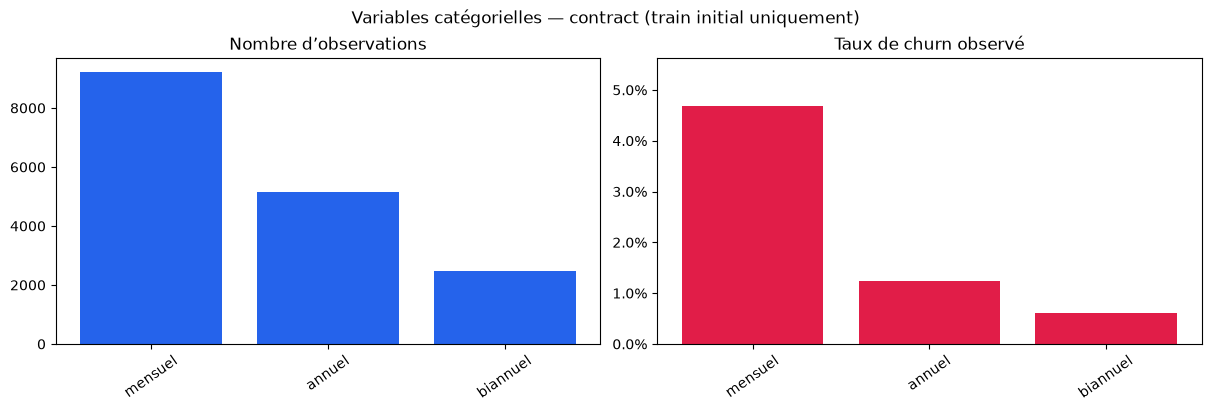

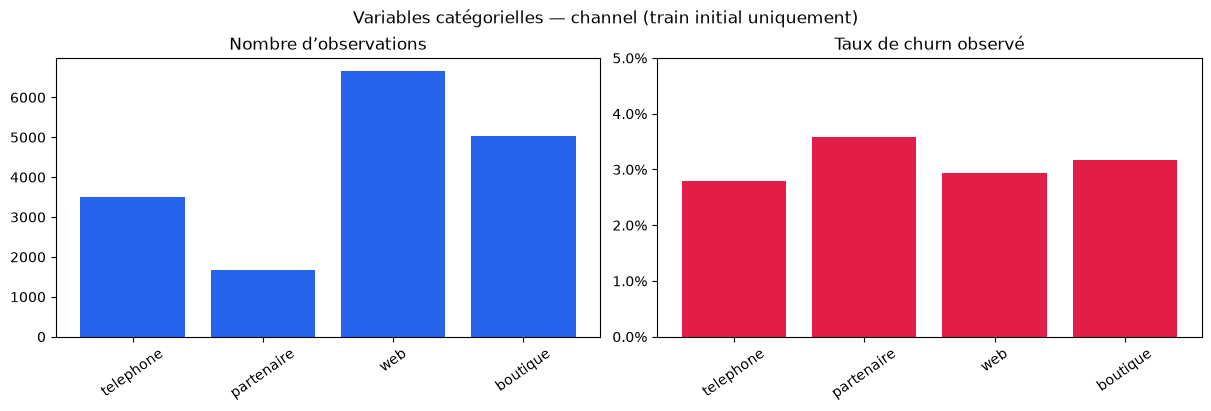

In [41]:
categorical_summary, categorical_groups = analyze_categorical_features(
    analysis_data, CATEGORICAL_FEATURES,
)
display(categorical_summary.round(4))
for feature, table in categorical_groups.items():
    print(feature)
    display(table.round(4))
plot_group_analysis(categorical_groups, "Variables catégorielles")


## 2.4 — Analyser les variables numériques

Examiner valeurs manquantes, constantes, amplitudes et extrêmes, puis churn par niveaux. Les groupes incluent les valeurs manquantes : ce mécanisme peut être prédictif. Une corrélation faible ne prouve pas une absence d’utilité dans CatBoost.


,missing_pct,valeurs_distinctes,minimum,médiane,maximum,extrêmes_iqr_pct,spearman_churn,all_missing,constant
feature,,,,,,,,,
monthly_fee,5.2216,6413,11.24,60.09,123.2,0.3193,0.0312,False,False
data_gb,0.0000,409,0.00,3.70,32154.0,5.9396,-0.0413,False,False
support_calls_3m,0.0000,11,0.00,1.00,10.0,0.4272,0.1081,False,False
late_payments,0.0000,6,0.00,0.00,5.0,0.9850,0.0694,False,False
nps,67.1394,11,-0.00,7.00,10.0,0.0722,-0.0592,False,False
last_invoice_amount,0.0000,6680,3.33,59.48,123.2,0.5518,-0.2174,False,False


monthly_fee


,groupe,observations,churns,taux_churn
0,"(11.239, 45.1]",3196,81,0.0253
1,"(45.1, 55.75]",3195,78,0.0244
2,"(55.75, 64.82]",3194,86,0.0269
3,"(64.82, 75.516]",3193,112,0.0351
4,"(75.516, 123.2]",3195,125,0.0391
5,Non renseigné,880,30,0.0341


data_gb


,groupe,observations,churns,taux_churn
0,"(-0.001, 1.5]",3443,138,0.0401
1,"(1.5, 2.8]",3310,121,0.0366
2,"(2.8, 4.7]",3498,98,0.0280
3,"(4.7, 7.8]",3247,78,0.0240
4,"(7.8, 32154.0]",3355,77,0.0230


support_calls_3m


... (3 outputs left out)

nps


,groupe,observations,churns,taux_churn
0,"(-0.001, 5.0]",1501,76,0.0506
1,"(5.0, 6.0]",982,42,0.0428
2,"(6.0, 7.0]",1013,25,0.0247
3,"(7.0, 9.0]",1472,44,0.0299
4,"(9.0, 10.0]",570,11,0.0193
5,Non renseigné,11315,314,0.0278


last_invoice_amount


,groupe,observations,churns,taux_churn
0,"(3.329, 44.03]",3375,381,0.1129
1,"(44.03, 55.0]",3367,75,0.0223
2,"(55.0, 64.222]",3370,32,0.0095
3,"(64.222, 75.01]",3372,16,0.0047
4,"(75.01, 123.2]",3369,8,0.0024


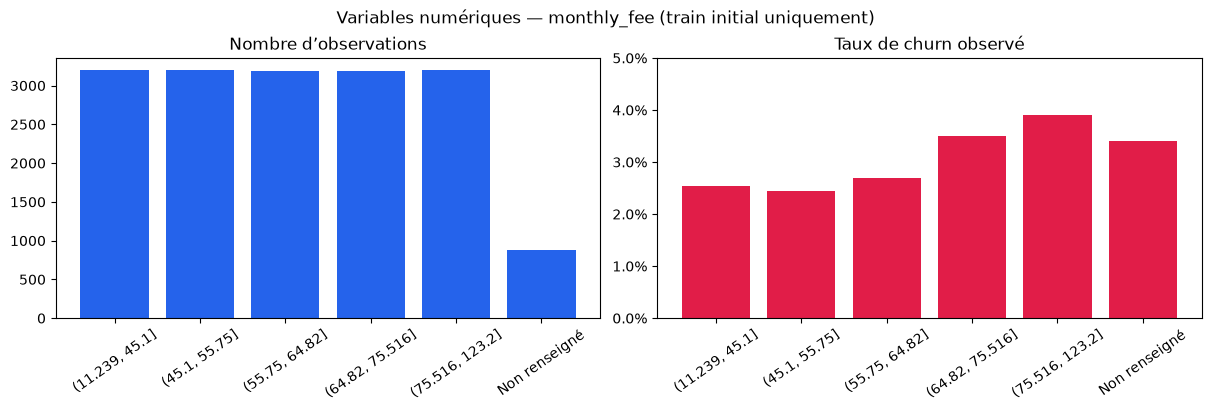

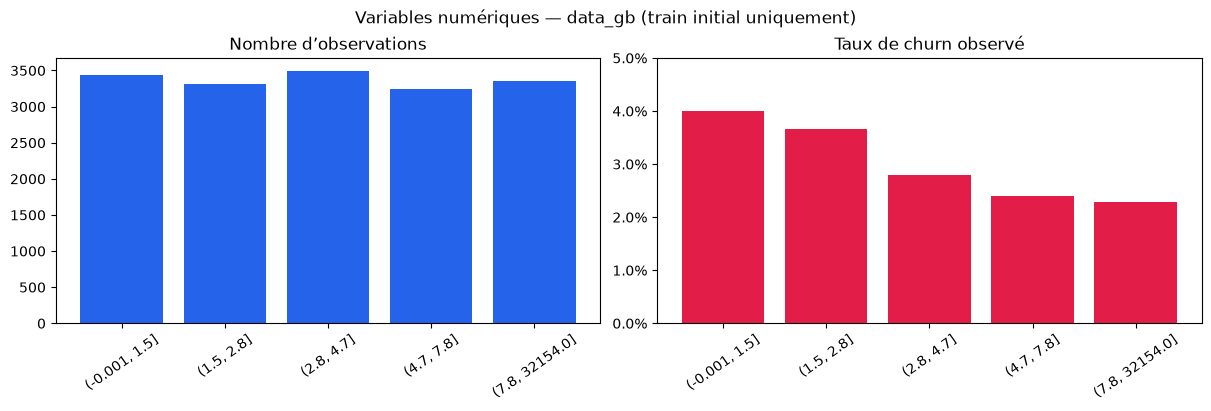

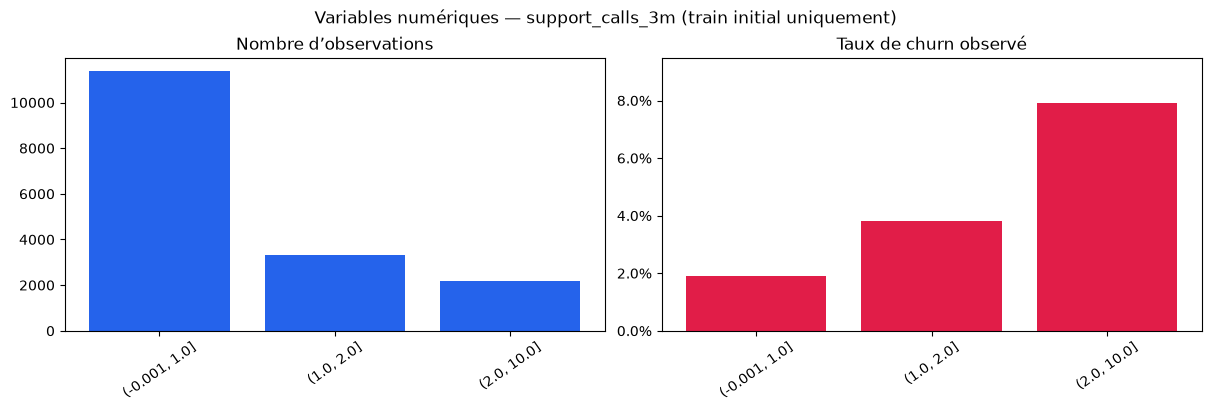

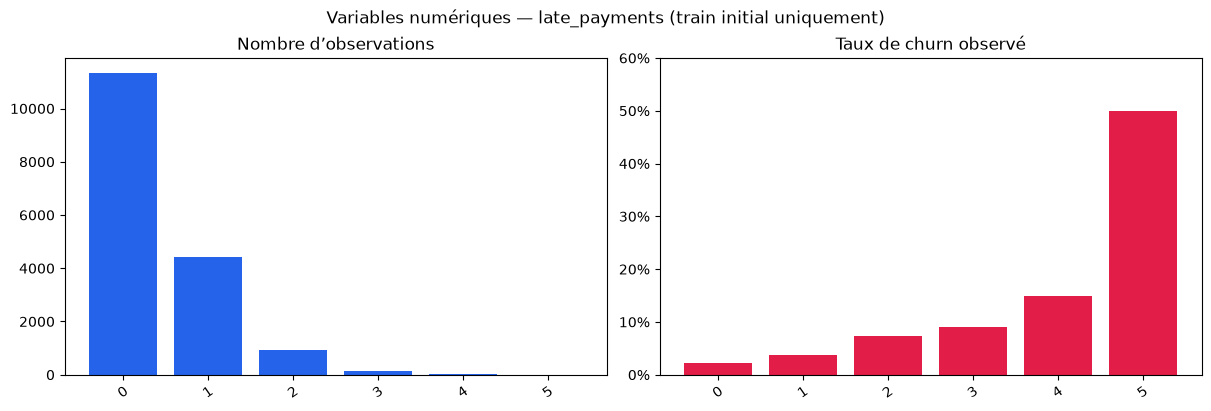

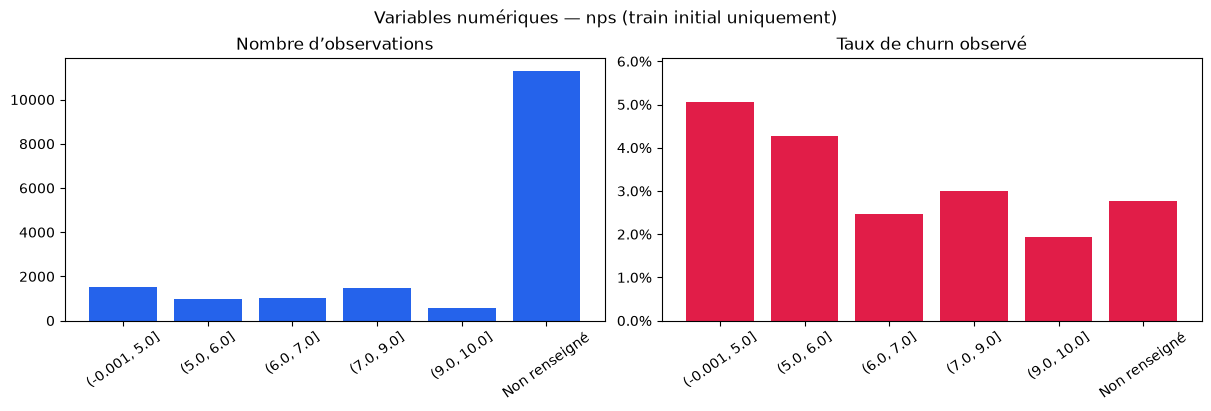

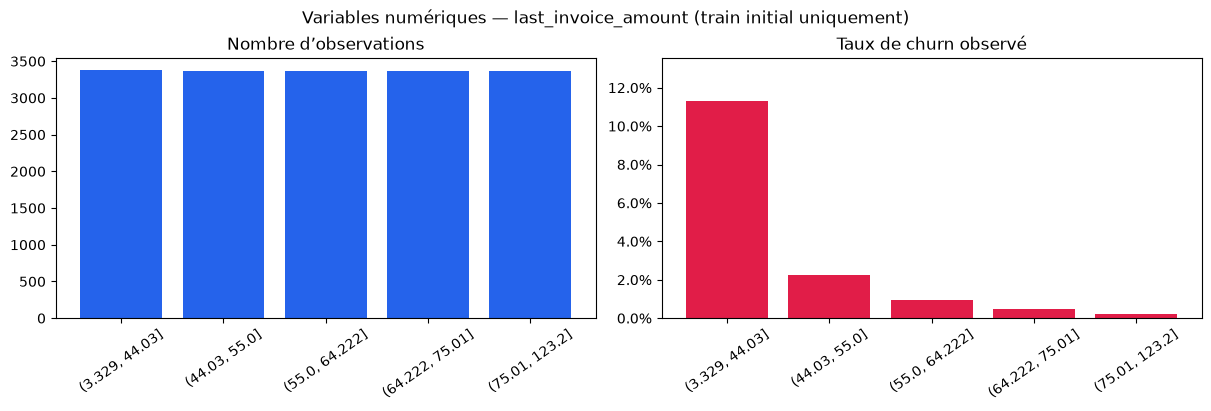

,monthly_fee,data_gb,support_calls_3m,late_payments,nps,last_invoice_amount
monthly_fee,1.000,-0.011,0.008,0.008,0.020,0.957
data_gb,-0.011,1.000,-0.013,0.004,-0.007,-0.002
support_calls_3m,0.008,-0.013,1.000,0.059,-0.240,-0.020
late_payments,0.008,0.004,0.059,1.000,-0.116,-0.011
nps,0.020,-0.007,-0.240,-0.116,1.000,0.036
last_invoice_amount,0.957,-0.002,-0.020,-0.011,0.036,1.000


In [42]:
numeric_summary, numeric_groups = analyze_numeric_features(analysis_data, NUMERIC_FEATURES)
display(numeric_summary.round(4))
for feature, table in numeric_groups.items():
    print(feature)
    display(table.round(4))
plot_group_analysis(numeric_groups, "Variables numériques")

# Corrélations entre prédicteurs : signaler la redondance, sans supprimer automatiquement.
display(analysis_data[NUMERIC_FEATURES].corr(method="spearman").round(3))
quality = pd.concat([
    categorical_summary[["all_missing", "constant"]],
    numeric_summary[["all_missing", "constant"]],
])


## 2.5 — Référence : toutes les variables sources

La référence utilise huit variables d’origine. On conserve ses trois modèles de validation pour calculer la permutation, sans consulter le test.


In [43]:
reference = run_validation(
    "Toutes les variables", model_data, MODEL_FEATURES, CATEGORICAL_FEATURES,
)
display(compare_experiments([reference], "Validation").round(4))



=== Toutes les variables : validation ===

Mois prédit : 2024-07 — poids des classes : {0: 0.5156661159047794, 1: 16.4580078125}
0:	learn: 0.6400596	test: 0.6344564	best: 0.6344564 (0)	total: 98ms	remaining: 2m 56s
50:	learn: 0.9537801	test: 0.9150759	best: 0.9159917 (49)	total: 712ms	remaining: 24.4s
100:	learn: 0.9831576	test: 0.9429761	best: 0.9429761 (100)	total: 1.23s	remaining: 20.6s
150:	learn: 0.9928940	test: 0.9499059	best: 0.9504849 (146)	total: 1.93s	remaining: 21.1s
200:	learn: 0.9956561	test: 0.9550084	best: 0.9552888 (199)	total: 2.51s	remaining: 19.9s
250:	learn: 0.9977281	test: 0.9588782	best: 0.9588782 (250)	total: 3.05s	remaining: 18.8s
300:	learn: 0.9985584	test: 0.9618483	best: 0.9626255 (293)	total: 3.63s	remaining: 18.1s
350:	learn: 0.9992637	test: 0.9659418	best: 0.9659794 (347)	total: 4.41s	remaining: 18.2s
400:	learn: 0.9995468	test: 0.9668978	best: 0.9669033 (397)	total: 4.9s	remaining: 17.1s
450:	learn: 0.9997024	test: 0.9685981	best: 0.9685981 (449)	total: 

,Average Precision,ROC-AUC,Logloss,F1,Precision,Recall,Variables,Seuil
Modèle,,,,,,,,
Toutes les variables,0.9813,0.996,0.0131,0.944,0.9736,0.9161,8,0.7668


## 2.6 — Proposer les variables à retirer

Les permutations sont répétées dans chacun des trois mois de validation. Le tableau et les analyses servent à proposer des retraits ; aucune colonne n’est retirée à ce stade.


In [44]:
permutation_details = validation_permutation_importance(reference, PERMUTATION_REPEATS)
candidates, selection_summary = propose_candidates(
    quality, permutation_details, PERMUTATION_TOLERANCE, MANUAL_CANDIDATES,
)
display(selection_summary.round(5))
display(permutation_details.groupby(["feature", "mois"])["ap_drop"].mean().unstack().round(5))
print("Retraits à vérifier :", candidates)


,baisse_ap_moyenne,variabilité,all_missing,constant,candidat
feature,,,,,
channel,-0.00083,0.00127,False,False,True
nps,-0.00057,0.00146,False,False,True
data_gb,0.00003,0.00236,False,False,True
support_calls_3m,0.00034,0.00280,False,False,True
late_payments,0.00226,0.00278,False,False,False
contract,0.00580,0.00359,False,False,False
monthly_fee,0.75716,0.03698,False,False,False
last_invoice_amount,0.93157,0.01360,False,False,False


mois,2024-07,2024-08,2024-09
feature,,,
channel,-0.00071,-0.00035,-0.00142
contract,0.00938,0.00349,0.00454
data_gb,0.00244,-0.00086,-0.00148
last_invoice_amount,0.94043,0.93843,0.91585
late_payments,0.00383,0.00158,0.00136
monthly_fee,0.74325,0.79905,0.72917
nps,-0.00050,-0.00056,-0.00066
support_calls_3m,0.00170,0.00129,-0.00196


Retraits à vérifier : ['channel', 'nps', 'data_gb', 'support_calls_3m']


## 2.7 — Sélectionner sur validation seulement

Chaque candidat déclenche trois entraînements supplémentaires. Les tolérances AP sont vérifiées sur chacun des trois mois ; la Logloss globale protège aussi la qualité des scores probabilistes. Aucune contrainte de répartition artificielle des importances n’est appliquée.


In [45]:
selected, selection_history = select_by_ablation(
    reference, candidates, AP_TOLERANCE, LOGLOSS_TOLERANCE,
)
display(selection_history)
print("Variables conservées :", selected["features"])
removed_features = []
for feature in MODEL_FEATURES:
    if feature not in selected["features"]:
        removed_features.append(feature)
print("Variables retirées :", removed_features)
experiments = [reference, selected]
display(compare_experiments(experiments, "Validation").round(4))



=== Essai sans channel : validation ===

Mois prédit : 2024-07 — poids des classes : {0: 0.5156661159047794, 1: 16.4580078125}
0:	learn: 0.7337242	test: 0.6822927	best: 0.6822927 (0)	total: 18.2ms	remaining: 32.8s
50:	learn: 0.9578344	test: 0.9228780	best: 0.9228780 (50)	total: 550ms	remaining: 18.9s
100:	learn: 0.9856629	test: 0.9513789	best: 0.9513789 (100)	total: 1.04s	remaining: 17.6s
150:	learn: 0.9924918	test: 0.9590591	best: 0.9592045 (149)	total: 1.56s	remaining: 17.1s
200:	learn: 0.9957866	test: 0.9624502	best: 0.9625593 (193)	total: 1.99s	remaining: 15.8s
250:	learn: 0.9974510	test: 0.9653456	best: 0.9656871 (217)	total: 2.46s	remaining: 15.2s
300:	learn: 0.9983770	test: 0.9684330	best: 0.9685005 (281)	total: 3s	remaining: 14.9s
350:	learn: 0.9992493	test: 0.9694685	best: 0.9694685 (350)	total: 3.46s	remaining: 14.3s
400:	learn: 0.9995589	test: 0.9701973	best: 0.9701973 (400)	total: 3.9s	remaining: 13.6s
450:	learn: 0.9996773	test: 0.9710202	best: 0.9710562 (444)	total: 4.35

,feature,retirée,plus_forte_perte_ap_mensuelle,variation_ap_globale,variation_logloss,raison
0,channel,False,0.001576,0.000473,-0.000123,retrait dégrade la validation au-delà des tolé...
1,nps,False,0.007396,-0.002880,0.000404,retrait dégrade la validation au-delà des tolé...
2,data_gb,False,0.003050,-0.003264,0.003273,retrait dégrade la validation au-delà des tolé...
3,support_calls_3m,False,0.000709,-0.002527,0.002180,retrait dégrade la validation au-delà des tolé...


Variables conservées : ['contract', 'channel', 'monthly_fee', 'data_gb', 'support_calls_3m', 'late_payments', 'nps', 'last_invoice_amount']
Variables retirées : []


,Average Precision,ROC-AUC,Logloss,F1,Precision,Recall,Variables,Seuil
Modèle,,,,,,,,
Toutes les variables,0.9813,0.996,0.0131,0.944,0.9736,0.9161,8,0.7668
Après sélection,0.9813,0.996,0.0131,0.944,0.9736,0.9161,8,0.7668


## 2.8 — Bilan de test avec les sélections fixées

Le même protocole d’octobre–novembre est appliqué aux deux modèles. Ne pas modifier la sélection ou ses tolérances après consultation de ce tableau.


In [46]:
for experiment in experiments:
    run_tests(experiment)
display(compare_experiments(experiments, "Test").round(4))
for experiment in experiments:
    print(experiment["name"])
    display(get_monthly_metrics(experiment).round(4))



=== Toutes les variables : test ===

Mois prédit : 2024-10 — poids des classes : {0: 0.5158822842461754, 1: 16.240808823529413}
0:	learn: 0.7986489	test: 0.8044856	best: 0.8044856 (0)	total: 34.4ms	remaining: 1m 1s
50:	learn: 0.9601988	test: 0.9158876	best: 0.9158876 (50)	total: 790ms	remaining: 27.1s
100:	learn: 0.9812817	test: 0.9398931	best: 0.9418976 (94)	total: 1.48s	remaining: 24.9s
150:	learn: 0.9886853	test: 0.9468078	best: 0.9470742 (149)	total: 2.27s	remaining: 24.8s
200:	learn: 0.9924845	test: 0.9492073	best: 0.9493744 (192)	total: 2.96s	remaining: 23.6s
250:	learn: 0.9949698	test: 0.9522207	best: 0.9522207 (250)	total: 3.61s	remaining: 22.3s
300:	learn: 0.9972934	test: 0.9568855	best: 0.9568855 (300)	total: 4.29s	remaining: 21.4s
350:	learn: 0.9986297	test: 0.9587032	best: 0.9590598 (344)	total: 5.03s	remaining: 20.8s
400:	learn: 0.9992519	test: 0.9608300	best: 0.9608939 (395)	total: 5.82s	remaining: 20.3s
450:	learn: 0.9995366	test: 0.9612627	best: 0.9613509 (449)	total: 

,Average Precision,ROC-AUC,Logloss,F1,Precision,Recall,Variables,Seuil
Modèle,,,,,,,,
Toutes les variables,0.9861,0.9978,0.0105,0.9718,0.9942,0.9503,8,0.7668
Après sélection,0.9861,0.9978,0.0105,0.9718,0.9942,0.9503,8,0.7668


Toutes les variables


,Average Precision,ROC-AUC,Logloss,F1,Precision,Recall,Meilleure itération
Mois,,,,,,,
2024-07,0.9847,0.9993,0.0127,0.9302,0.9804,0.8850,843
2024-08,0.9929,0.9997,0.0088,0.9686,0.9818,0.9558,896
2024-09,0.9624,0.9877,0.0179,0.9305,0.9560,0.9062,760
2024-10,0.9875,0.9996,0.0136,0.9576,0.9875,0.9294,463
2024-11,0.9864,0.9987,0.0073,0.9841,1.0000,0.9688,1218


Après sélection


,Average Precision,ROC-AUC,Logloss,F1,Precision,Recall,Meilleure itération
Mois,,,,,,,
2024-07,0.9847,0.9993,0.0127,0.9302,0.9804,0.8850,843
2024-08,0.9929,0.9997,0.0088,0.9686,0.9818,0.9558,896
2024-09,0.9624,0.9877,0.0179,0.9305,0.9560,0.9062,760
2024-10,0.9875,0.9996,0.0136,0.9576,0.9875,0.9294,463
2024-11,0.9864,0.9987,0.0073,0.9841,1.0000,0.9688,1218


## 2.9 — Courbes d’apprentissage

Le modèle affiché par défaut est novembre, avec janvier–septembre au train et octobre en validation interne.


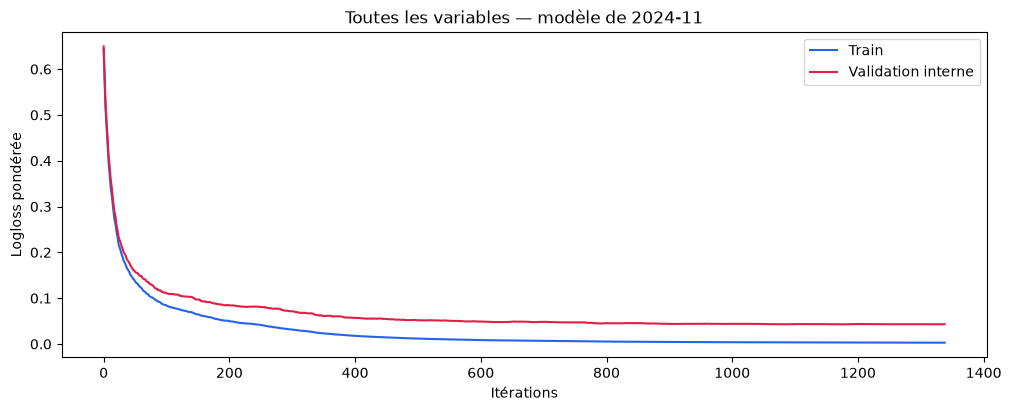

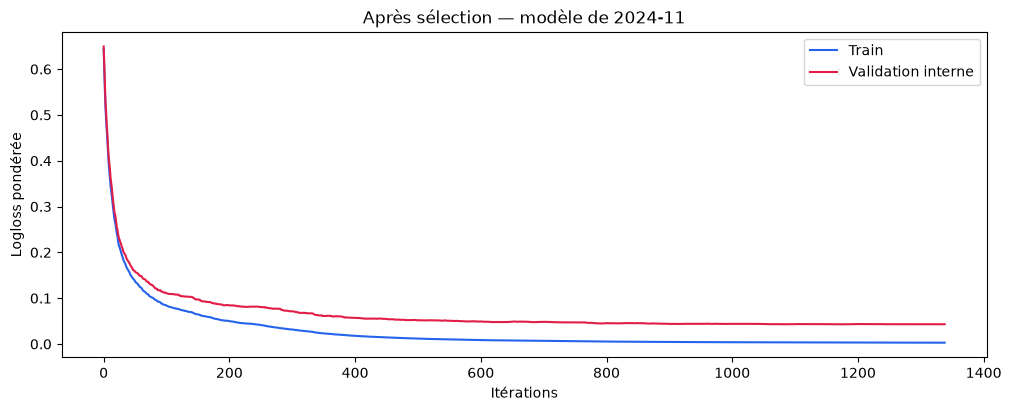

In [47]:
for experiment in experiments:
    plot_learning_curve(experiment, DISPLAY_MONTH)


## 2.10 — Matrices de confusion

Pour chaque version : validation juillet–septembre et test octobre–novembre côte à côte, effectifs puis pourcentages normalisés par classe réelle.


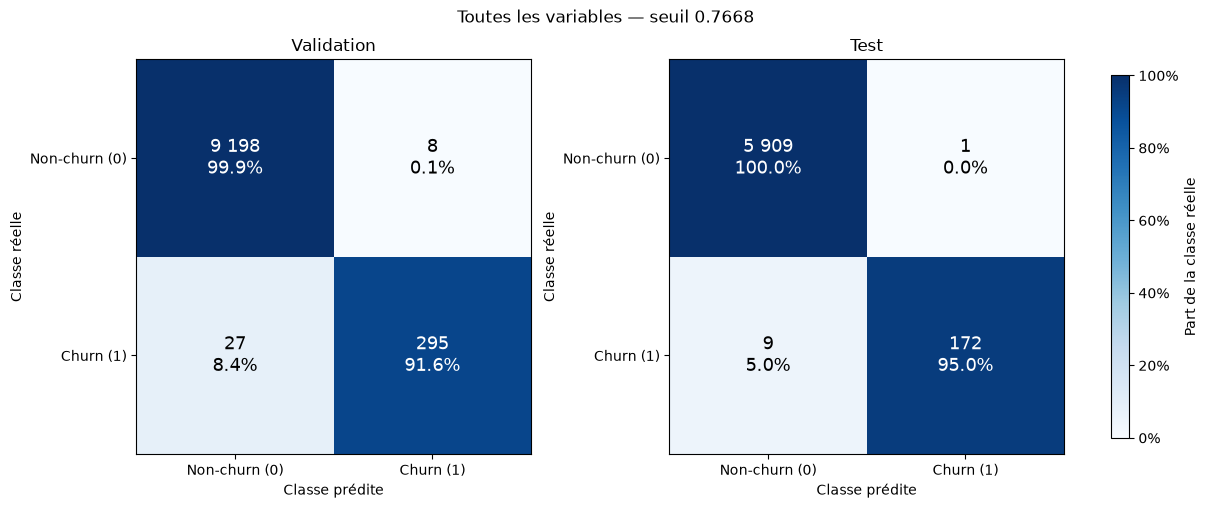

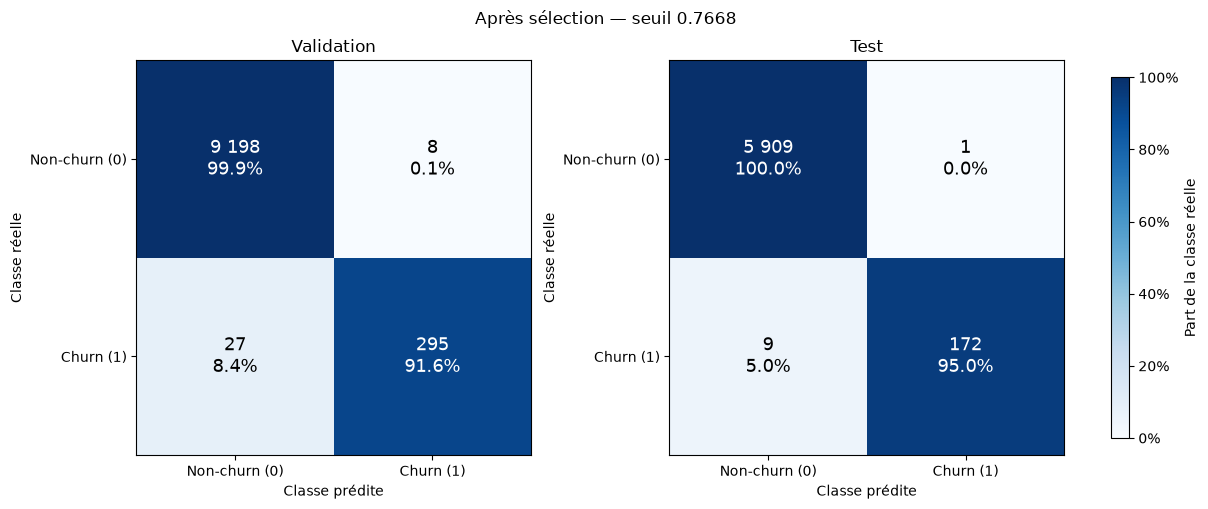

In [48]:
for experiment in experiments:
    plot_confusion_matrices(experiment)


## 2.11 — Importance des variables conservées

Le graphique décrit le dernier modèle mensuel, pas une causalité ou une preuve d’équivalence. Le critère de sélection reste l’ablation sur validation.


,rank,feature,importance
0,1,monthly_fee,48.057590
1,2,last_invoice_amount,34.401430
2,3,data_gb,3.911004
3,4,contract,3.551872
4,5,support_calls_3m,3.537459
5,6,late_payments,2.941715
6,7,nps,1.940205
7,8,channel,1.658726


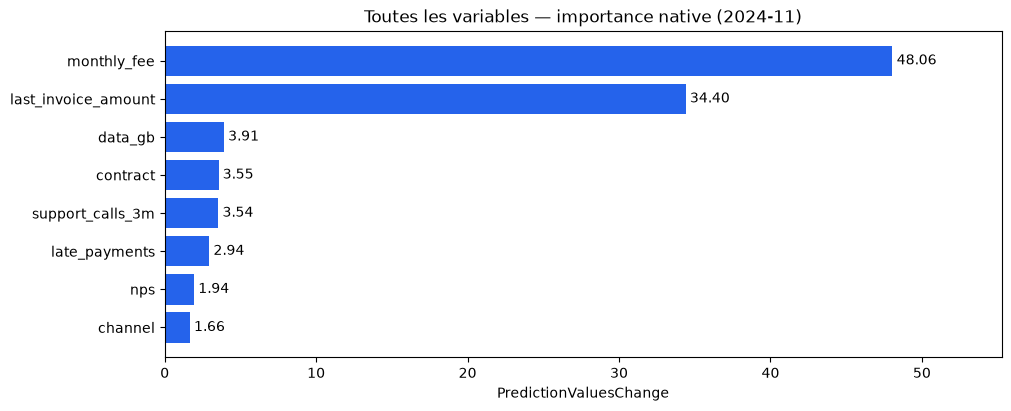

,rank,feature,importance
0,1,monthly_fee,48.057590
1,2,last_invoice_amount,34.401430
2,3,data_gb,3.911004
3,4,contract,3.551872
4,5,support_calls_3m,3.537459
5,6,late_payments,2.941715
6,7,nps,1.940205
7,8,channel,1.658726


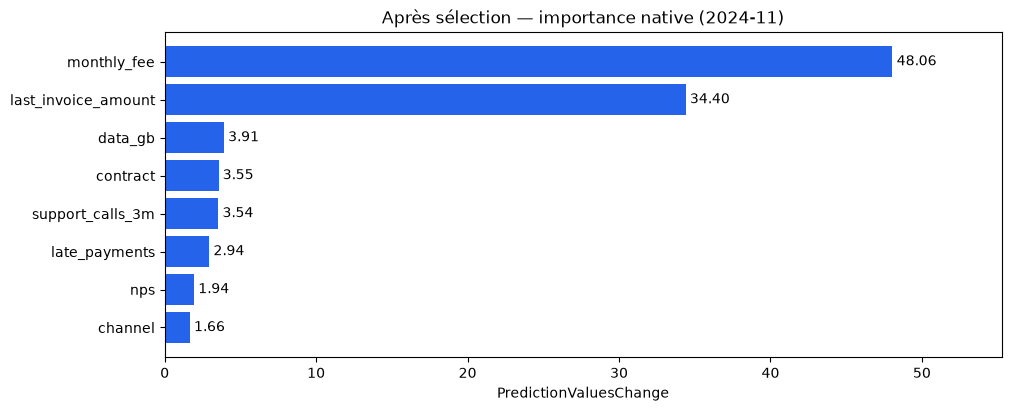

In [49]:
for experiment in experiments:
    plot_feature_importance(experiment, DISPLAY_MONTH)
